In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

matches = pd.read_csv("data/matches_clean.csv")
print(matches.shape)

(1095, 20)


In [3]:
valid = matches[matches["winner"] != "No Result"].copy()
valid["toss_win_match_win"] = valid["toss_winner"] == valid["winner"]

pct = valid["toss_win_match_win"].mean() * 100
print("Matches (result wale):", len(valid))
print(f"Toss jeetne wali team ne match jeeta: {pct:.1f}%")

print(valid.groupby("toss_decision")["toss_win_match_win"].mean() * 100)

Matches (result wale): 1090
Toss jeetne wali team ne match jeeta: 50.8%
toss_decision
bat      45.384615
field    53.857143
Name: toss_win_match_win, dtype: float64


toss_decision
field    700
bat      390
Name: count, dtype: int64


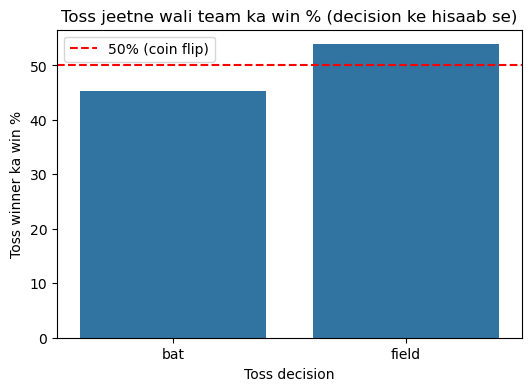

In [4]:
print(valid["toss_decision"].value_counts())

win_pct = valid.groupby("toss_decision")["toss_win_match_win"].mean() * 100

plt.figure(figsize=(6, 4))
sns.barplot(x=win_pct.index, y=win_pct.values)
plt.axhline(50, color="red", linestyle="--", label="50% (coin flip)")
plt.ylabel("Toss winner ka win %")
plt.xlabel("Toss decision")
plt.title("Toss jeetne wali team ka win % (decision ke hisaab se)")
plt.legend()
plt.show()

In [10]:
import numpy as np


other_team = np.where(valid["toss_winner"] == valid["team1"], valid["team2"], valid["team1"])
valid["bat_first"] = np.where(valid["toss_decision"] == "bat", valid["toss_winner"], other_team)


valid["chasing_won"] = valid["winner"] != valid["bat_first"]

print(f"Chase karne wali team ka win %: {valid['chasing_won'].mean() * 100:.1f}%")


venue_stats = valid.groupby("venue").agg(
    matches=("chasing_won", "size"),
    chase_win_pct=("chasing_won", lambda x: x.mean() * 100)
)
venue_stats = venue_stats[venue_stats["matches"] >= 20].sort_values("chase_win_pct", ascending=False)
print(venue_stats.round(1))

Chase karne wali team ka win %: 54.1%
                                                    matches  chase_win_pct
venue                                                                     
Sawai Mansingh Stadium, Jaipur                           57           64.9
Sharjah Cricket Stadium                                  28           64.3
Eden Gardens, Kolkata                                    93           59.1
Narendra Modi Stadium, Ahmedabad                         36           58.3
Sheikh Zayed Stadium, Abu Dhabi                          37           56.8
Rajiv Gandhi International Stadium, Hyderabad            77           55.8
Punjab Cricket Association IS Bindra Stadium, M...       61           55.7
M Chinnaswamy Stadium, Bengaluru                         91           54.9
Wankhede Stadium, Mumbai                                118           54.2
Dr DY Patil Sports Academy, Mumbai                       37           54.1
Arun Jaitley Stadium, Delhi                              89   

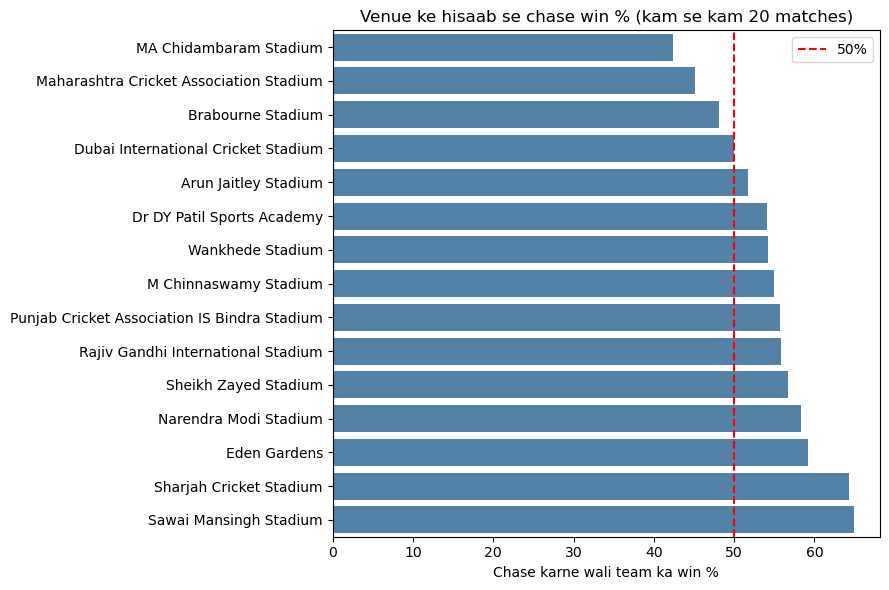

In [6]:
import os
os.makedirs("images", exist_ok=True)

plot_df = venue_stats.copy()
plot_df["short_name"] = plot_df.index.str.split(",").str[0]
plot_df = plot_df.sort_values("chase_win_pct")

plt.figure(figsize=(9, 6))
sns.barplot(data=plot_df, x="chase_win_pct", y="short_name", color="steelblue")
plt.axvline(50, color="red", linestyle="--", label="50%")
plt.xlabel("Chase karne wali team ka win %")
plt.ylabel("")
plt.title("Venue ke hisaab se chase win % (kam se kam 20 matches)")
plt.legend()
plt.tight_layout()
plt.savefig("images/chase_by_venue.png", dpi=150)
plt.show()

In [7]:
df = pd.read_csv("data/ipl_clean.csv")
print(df.shape)
print(df["extras_type"].unique())

(260920, 25)
['legbyes' nan 'wides' 'byes' 'noballs' 'penalty']


In [9]:

bat = df[df["extras_type"] != "wides"].copy()

bat["is_four"] = bat["batsman_runs"] == 4
bat["is_six"] = bat["batsman_runs"] == 6

stats = bat.groupby("batter").agg(
    runs=("batsman_runs", "sum"),
    balls=("batsman_runs", "size"),
    fours=("is_four", "sum"),
    sixes=("is_six", "sum"),
)


outs = df[df["player_dismissed"].notnull()].groupby("player_dismissed").size()
stats["outs"] = outs
stats["outs"] = stats["outs"].fillna(0)

stats["strike_rate"] = stats["runs"] / stats["balls"] * 100
stats["boundary_pct"] = (stats["fours"] + stats["sixes"]) / stats["balls"] * 100
stats["avg"] = stats["runs"] / stats["outs"].replace(0, float("nan"))


top = stats[stats["balls"] >= 1000].sort_values("runs", ascending=False)
print(top.head(15).round(1))

                runs  balls  fours  sixes   outs  strike_rate  boundary_pct  \
batter                                                                        
V Kohli         8014   6069    708    273  207.0        132.0          16.2   
S Dhawan        6769   5326    768    153  193.0        127.1          17.3   
RG Sharma       6630   5057    599    281  223.0        131.1          17.4   
DA Warner       6567   4702    663    236  164.0        139.7          19.1   
SK Raina        5536   4046    506    204  171.0        136.8          17.5   
MS Dhoni        5243   3812    363    252  134.0        137.5          16.1   
AB de Villiers  5181   3411    414    253  130.0        151.9          19.6   
CH Gayle        4997   3346    408    359  126.0        149.3          22.9   
RV Uthappa      4954   3801    481    182  180.0        130.3          17.4   
KD Karthik      4843   3580    466    161  184.0        135.3          17.5   
KL Rahul        4689   3485    400    187  105.0    

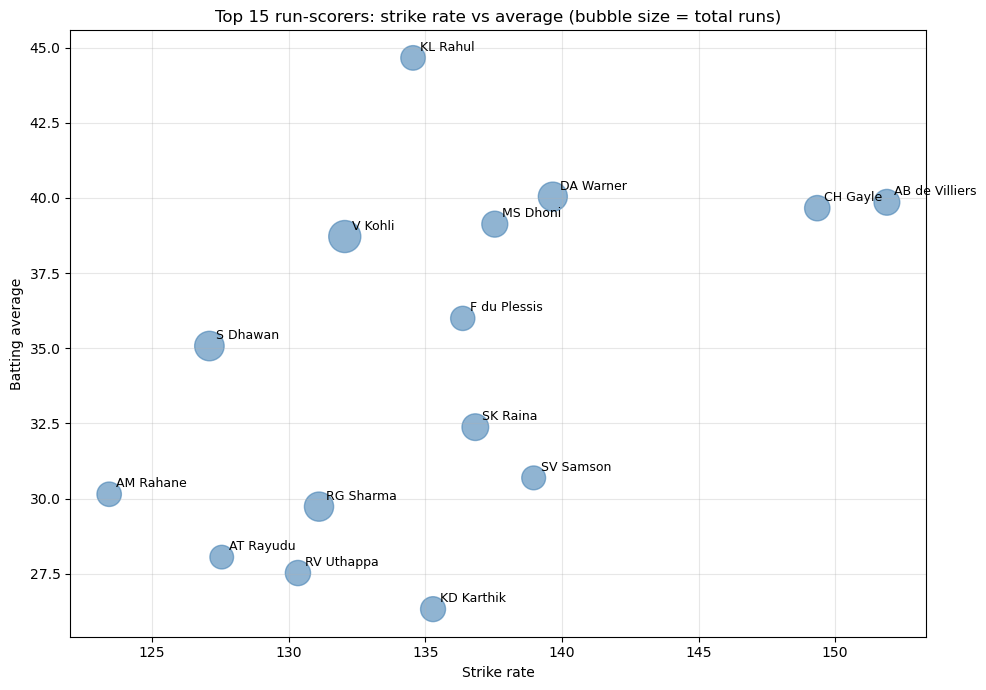

In [11]:
plot_top = top.head(15).copy()

plt.figure(figsize=(10, 7))
plt.scatter(plot_top["strike_rate"], plot_top["avg"],
            s=plot_top["runs"] / 15, alpha=0.6, color="steelblue")

for name, row in plot_top.iterrows():
    plt.annotate(name, (row["strike_rate"], row["avg"]), fontsize=9,
                 xytext=(5, 5), textcoords="offset points")

plt.xlabel("Strike rate")
plt.ylabel("Batting average")
plt.title("Top 15 run-scorers: strike rate vs average (bubble size = total runs)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("images/batsmen_sr_vs_avg.png", dpi=150)
plt.show()

In [12]:
print(df["dismissal_kind"].unique())

[nan 'caught' 'bowled' 'run out' 'lbw' 'retired hurt' 'stumped'
 'caught and bowled' 'hit wicket' 'obstructing the field' 'retired out']


In [13]:
import numpy as np

bowl = df.copy()

# Byes, legbyes aur penalty ke runs bowler ke naam nahi lagte
bowl["bowler_runs"] = np.where(
    bowl["extras_type"].isin(["legbyes", "byes", "penalty"]), 0, bowl["total_runs"]
)

# Wides aur no-balls legal delivery nahi hoti
legal = bowl[~bowl["extras_type"].isin(["wides", "noballs"])]

# Bowler ke wickets (run out waghera nahi)
not_bowler = ["run out", "retired hurt", "retired out", "obstructing the field"]
bowl["bowler_wkt"] = (bowl["is_wicket"] == 1) & (~bowl["dismissal_kind"].isin(not_bowler))

stats_b = pd.DataFrame({
    "balls": legal.groupby("bowler").size(),
    "dots": legal[legal["bowler_runs"] == 0].groupby("bowler").size(),
    "runs": bowl.groupby("bowler")["bowler_runs"].sum(),
    "wickets": bowl.groupby("bowler")["bowler_wkt"].sum(),
}).fillna(0)

stats_b["economy"] = stats_b["runs"] / stats_b["balls"] * 6
stats_b["dot_pct"] = stats_b["dots"] / stats_b["balls"] * 100
stats_b["bowling_sr"] = stats_b["balls"] / stats_b["wickets"].replace(0, float("nan"))

# Kam se kam 600 balls (100 overs) dale huye bowlers
top_b = stats_b[stats_b["balls"] >= 600].sort_values("wickets", ascending=False)
print(top_b.head(15).round(1))

                 balls    dots  runs  wickets  economy  dot_pct  bowling_sr
bowler                                                                     
YS Chahal         3521  1246.0  4602      205      7.8     35.4        17.2
PP Chawla         3850  1358.0  5108      192      8.0     35.3        20.1
DJ Bravo          3120  1054.0  4360      183      8.4     33.8        17.0
B Kumar           3910  1729.0  4929      181      7.6     44.2        21.6
SP Narine         4081  1631.0  4582      180      6.7     40.0        22.7
R Ashwin          4524  1606.0  5369      180      7.1     35.5        25.1
A Mishra          3371  1220.0  4145      174      7.4     36.2        19.4
SL Malinga        2828  1218.0  3364      170      7.1     43.1        16.6
JJ Bumrah         3075  1300.0  3743      168      7.3     42.3        18.3
RA Jadeja         3829  1261.0  4864      160      7.6     32.9        23.9
Harbhajan Singh   3416  1312.0  4030      150      7.1     38.4        22.8
Rashid Khan 

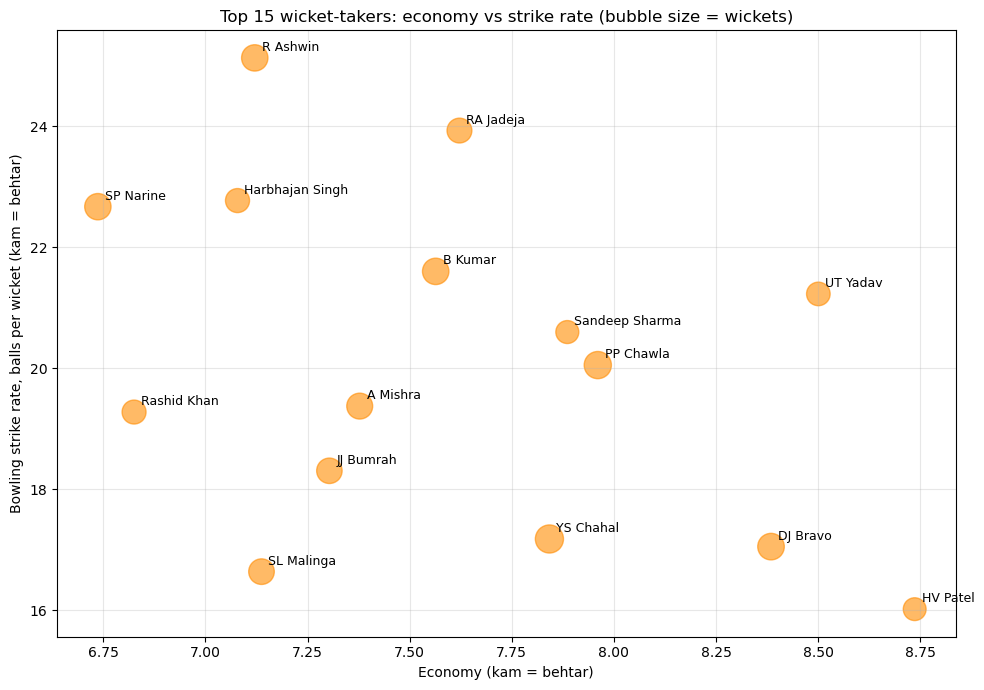

In [14]:
plot_b = top_b.head(15).copy()

plt.figure(figsize=(10, 7))
plt.scatter(plot_b["economy"], plot_b["bowling_sr"],
            s=plot_b["wickets"] * 2, alpha=0.6, color="darkorange")

for name, row in plot_b.iterrows():
    plt.annotate(name, (row["economy"], row["bowling_sr"]), fontsize=9,
                 xytext=(5, 5), textcoords="offset points")

plt.xlabel("Economy (kam = behtar)")
plt.ylabel("Bowling strike rate, balls per wicket (kam = behtar)")
plt.title("Top 15 wicket-takers: economy vs strike rate (bubble size = wickets)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("images/bowlers_econ_vs_sr.png", dpi=150)
plt.show()